In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from google.colab import files

# Upload the original MoMA dataset
uploaded = files.upload()

filename = next(iter(uploaded))

df = pd.read_csv(filename, low_memory=False)

print("Original dataset shape:", df.shape)
print("Original records:", len(df))
print("Columns:", df.columns.tolist())

df.head()

Saving Artworks.csv to Artworks (1).csv
Original dataset shape: (160700, 30)
Original records: 160700
Columns: ['Title', 'Artist', 'ConstituentID', 'ArtistBio', 'Nationality', 'BeginDate', 'EndDate', 'Gender', 'Date', 'Medium', 'Dimensions', 'CreditLine', 'AccessionNumber', 'Classification', 'Department', 'DateAcquired', 'Cataloged', 'ObjectID', 'URL', 'ImageURL', 'OnView', 'Circumference (cm)', 'Depth (cm)', 'Diameter (cm)', 'Height (cm)', 'Length (cm)', 'Weight (kg)', 'Width (cm)', 'Seat Height (cm)', 'Duration (sec.)']


,Title,Artist,ConstituentID,ArtistBio,Nationality,BeginDate,EndDate,Gender,Date,Medium,...,OnView,Circumference (cm),Depth (cm),Diameter (cm),Height (cm),Length (cm),Weight (kg),Width (cm),Seat Height (cm),Duration (sec.)
0,"Ferdinandsbrücke Project, Vienna, Austria (Ele...",Otto Wagner,6210,"(Austrian, 1841–1918)",(Austrian),(1841),(1918),(male),1896,Ink and cut-and-pasted painted pages on paper,...,NaN,NaN,NaN,NaN,48.6000,NaN,NaN,168.9000,NaN,NaN
1,"City of Music, National Superior Conservatory ...",Christian de Portzamparc,7470,"(French, born 1944)",(French),(1944),(0),(male),1987,Paint and colored pencil on print,...,NaN,NaN,NaN,NaN,40.6401,NaN,NaN,29.8451,NaN,NaN
2,"Villa project, outside Vienna, Austria (Elevat...",Emil Hoppe,7605,"(Austrian, 1876–1957)",(Austrian),(1876),(1957),(male),1903,"Graphite, pen, color pencil, ink, and gouache ...",...,NaN,NaN,NaN,NaN,34.3000,NaN,NaN,31.8000,NaN,NaN
3,"The Manhattan Transcripts Project, New York, N...",Bernard Tschumi,7056,"(French and Swiss, born Switzerland 1944)",(),(1944),(0),(male),1980,Photographic reproduction with colored synthet...,...,NaN,NaN,NaN,NaN,50.8000,NaN,NaN,50.8000,NaN,NaN
4,"Villa project, outside Vienna, Austria (Exteri...",Emil Hoppe,7605,"(Austrian, 1876–1957)",(Austrian),(1876),(1957),(male),1903,"Graphite, color pencil, ink, and gouache on tr...",...,NaN,NaN,NaN,NaN,38.4000,NaN,NaN,19.1000,NaN,NaN


In [5]:

# ============================================================
# 1. Expand shortened year ranges
# Example: 1960-65 -> 1960-1965
# ============================================================

def expand_short_year(start_year, end_text):
    start_year = int(start_year)
    end_text = str(end_text)

    if len(end_text) == 4:
        return int(end_text)

    digits = len(end_text)
    base = (start_year // (10 ** digits)) * (10 ** digits)
    end_year = base + int(end_text)

    if end_year < start_year:
        end_year += 10 ** digits

    return end_year


# ============================================================
# 2. Parse artwork creation dates
# ============================================================

def parse_moma_date(value, circa_pad=2):

    def result(lower, upper, date_type):
        return lower, upper, (lower + upper) / 2, date_type

    if pd.isna(value):
        return np.nan, np.nan, np.nan, "missing"

    s = str(value).lower().strip()
    s = s.replace("−", "-").replace("–", "-").replace("—", "-")
    s = re.sub(r"\s+", " ", s)

    # Remove outer parentheses
    while s.startswith("(") and s.endswith(")"):
        s = s[1:-1].strip()

    # Unknown dates
    unknown_pattern = (
        r"(?:n\.?\s*d\.?|unknown|unkown|tbd|tbc|"
        r"undated|no date|date unknown|not dated|various|\?)"
    )

    if re.fullmatch(unknown_pattern, s):
        return np.nan, np.nan, np.nan, "unknown"

    # BC / BCE: retained for consistency with previous n=3000
    m = re.search(
        r"(?:(c\.?|ca\.?|circa)\s*)?"
        r"(\d{1,4})\s*"
        r"(?:b\.?\s*c\.?\s*e?\.?|bce)\b",
        s
    )

    if m:
        y = -int(m.group(2))
        if m.group(1):
            return result(y - circa_pad, y + circa_pad, "circa_bc")
        return result(y, y, "bc")

    # Open-ended dates: do not guess a year
    open_patterns = [
        r"^(?:probably\s+)?before\s+\d{4}\??\.?$",
        r"^(?:probably\s+)?after\s+\d{4}\??\.?$",
        r"^\(?\s*(?:probably\s+)?before\s+\d{4}\s*\)?$",
        r"^\(?\s*(?:probably\s+)?after\s+\d{4}\s*\)?$",
        r"^\d{4}\s+(?:or\s+)?before\??\.?$",
        r"^\d{4}\s+(?:or\s+)?after\??\.?$"
    ]

    if any(re.fullmatch(p, s) for p in open_patterns):
        return np.nan, np.nan, np.nan, "open_ended_excluded"

    # Circa year ranges: c. 1938-60
    m = re.match(
        r"^(?:c\.?|ca\.?|circa)\s*(\d{4})\s*-\s*(\d{1,4})",
        s
    )

    if m:
        lower = int(m.group(1))
        upper = expand_short_year(lower, m.group(2))
        return result(lower, upper, "circa_range")

    # Circa single years: c. 1960
    m = re.match(r"^(?:c\.?|ca\.?|circa)\s*(\d{4})\b", s)

    if m:
        y = int(m.group(1))
        return result(y - circa_pad, y + circa_pad, "circa")

    # Alternative years: 1936 or 1937
    m = re.match(r"^(\d{4})\s+or\s+(\d{4})\b", s)

    if m:
        y1, y2 = int(m.group(1)), int(m.group(2))
        return result(min(y1, y2), max(y1, y2), "alternative_years")

    # Year ranges: 1960-1965 or 1960-65
    m = re.match(r"^(\d{4})\s*-\s*(\d{1,4})\b", s)

    if m:
        lower = int(m.group(1))
        upper = expand_short_year(lower, m.group(2))
        return result(lower, upper, "range")

    # Decades: early/mid/late 1960s
    m = re.match(
        r"^(early|mid(?:dle)?|late)?\s*(\d{4})s\b",
        s
    )

    if m:
        position = m.group(1) or ""
        base = int(m.group(2))

        if position == "early":
            lower, upper = base, base + 3
        elif position.startswith("mid"):
            lower, upper = base + 4, base + 6
        elif position == "late":
            lower, upper = base + 7, base + 9
        else:
            lower, upper = base, base + 9

        return result(lower, upper, "decade_" + (position or "full"))

    # Centuries: 19th century, late 19th century
    m = re.match(
        r"^(early|mid(?:dle)?|late)?\s*"
        r"(\d{1,2})(?:st|nd|rd|th)\s+century"
        r"(?:\s+c\.?e\.?)?",
        s
    )

    if m:
        position = m.group(1) or ""
        century = int(m.group(2))
        start = (century - 1) * 100
        end = century * 100 - 1

        if position == "early":
            lower, upper = start, start + 33
        elif position.startswith("mid"):
            lower, upper = start + 34, start + 66
        elif position == "late":
            lower, upper = start + 67, end
        else:
            lower, upper = start, end

        return result(lower, upper, "century_" + (position or "full"))

    # Century ranges: 4th-6th century C.E.
    m = re.match(
        r"^(\d{1,2})(?:st|nd|rd|th)\s*-\s*"
        r"(\d{1,2})(?:st|nd|rd|th)\s+century"
        r"(?:\s+c\.?e\.?)?",
        s
    )

    if m:
        c1, c2 = int(m.group(1)), int(m.group(2))
        return result((c1 - 1) * 100, c2 * 100 - 1, "century_range")

    # Exact primary year
    m = re.match(r"^(\d{4})(?!\d)", s)

    if m:
        y = int(m.group(1))
        return result(y, y, "primary_exact_year")

    # Calendar dates: March 12, 1960
    month_pattern = (
        r"^(?:january|february|march|april|may|june|"
        r"july|august|september|october|november|december)"
    )

    if re.match(month_pattern, s):
        m = re.search(r"(?<!\d)(\d{4})(?!\d)", s)
        if m:
            y = int(m.group(1))
            return result(y, y, "calendar_date")

    # Publication-only dates are not creation years
    if re.match(r"^(published|printed|publication|edition)\b", s):
        return np.nan, np.nan, np.nan, "publication_only_excluded"

    # Fallback: first identifiable four-digit year
    m = re.search(r"(?<!\d)(\d{4})(?!\d)", s)

    if m:
        y = int(m.group(1))
        return result(y, y, "fallback_embedded_year")

    return np.nan, np.nan, np.nan, "unparsed"


# ============================================================
# 3. Apply data cleaning
# ============================================================

parsed = df["Date"].apply(parse_moma_date).apply(pd.Series)

parsed.columns = [
    "year_lower",
    "year_upper",
    "year_mid",
    "date_type"
]

df_clean = pd.concat([df, parsed], axis=1)

# Use the same population definition as previous n=3000
years = df_clean["year_mid"].dropna().astype(float)

# ============================================================
# 4. Check cleaned data
# ============================================================

print("Original records:", len(df))
print("Usable records:", len(years))
print("Population mean:", round(years.mean(), 3))
print("Population SD:", round(years.std(ddof=0), 3))

print("\nDate types:")
print(df_clean["date_type"].value_counts())

print("\nExamples of cleaned dates:")
print(
    df_clean[
        ["Date", "year_lower", "year_upper", "year_mid", "date_type"]
    ].head(20)
)

# ============================================================
# 5. Save cleaned dataset
# ============================================================

df_clean.to_csv("Artworks_cleaned_all.csv", index=False)

print("\nCleaned dataset saved successfully.")

# Check consistency with previous experiment
if len(years) != 155119 or not np.isclose(
    years.mean(), 1956.712, atol=0.01
):
    print("WARNING: Results differ from the original n=3000 dataset.")
    print("Check the source CSV and date cleaning rules.")


Original records: 160700
Usable records: 155120
Population mean: 1956.68
Population SD: 36.3

Date types:
date_type
primary_exact_year           107660
range                         32169
circa                          7376
calendar_date                  3430
unknown                        2400
circa_range                    2122
missing                        2016
fallback_embedded_year         1394
decade_full                     645
publication_only_excluded       619
open_ended_excluded             540
decade_early                    275
decade_late                      30
alternative_years                12
unparsed                          5
century_range                     2
century_full                      2
century_late                      1
circa_bc                          1
decade_mid                        1
Name: count, dtype: int64

Examples of cleaned dates:
       Date  year_lower  year_upper  year_mid           date_type
0      1896      1896.0      1896.0    1896.

In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

# =========================================
# 1. Load cleaned MoMA data
# =========================================

# Use the data already cleaned in your notebook
if "years" in globals():
    values = pd.to_numeric(
        pd.Series(years), errors="coerce"
    ).dropna().to_numpy(dtype=float)

elif "df_clean" in globals():
    values = pd.to_numeric(
        df_clean["year_mid"], errors="coerce"
    ).dropna().to_numpy(dtype=float)

else:
    raise NameError(
        "Please run the Data Cleaning section first."
    )

values = values[np.isfinite(values)]

# Population reference statistics
true_mu = values.mean()
N = len(values)

print(f"Number of artworks: {N}")
print(f"Mean creation year: {true_mu:.2f}")

# =========================================
# 2. Define hypothetical Normal priors
# =========================================

priors = {
    "Weak Prior": {
        "mean": 1950,
        "sd": 20
    },
    "Strong Prior": {
        "mean": 1950,
        "sd": 3
    }
}

print("\nPrior distributions:")

for name, parameters in priors.items():
    print(
        f"{name}: "
        f"Mean = {parameters['mean']}, "
        f"SD = {parameters['sd']}"
    )


Number of artworks: 155120
Mean creation year: 1956.68

Prior distributions:
Weak Prior: Mean = 1950, SD = 20
Strong Prior: Mean = 1950, SD = 3


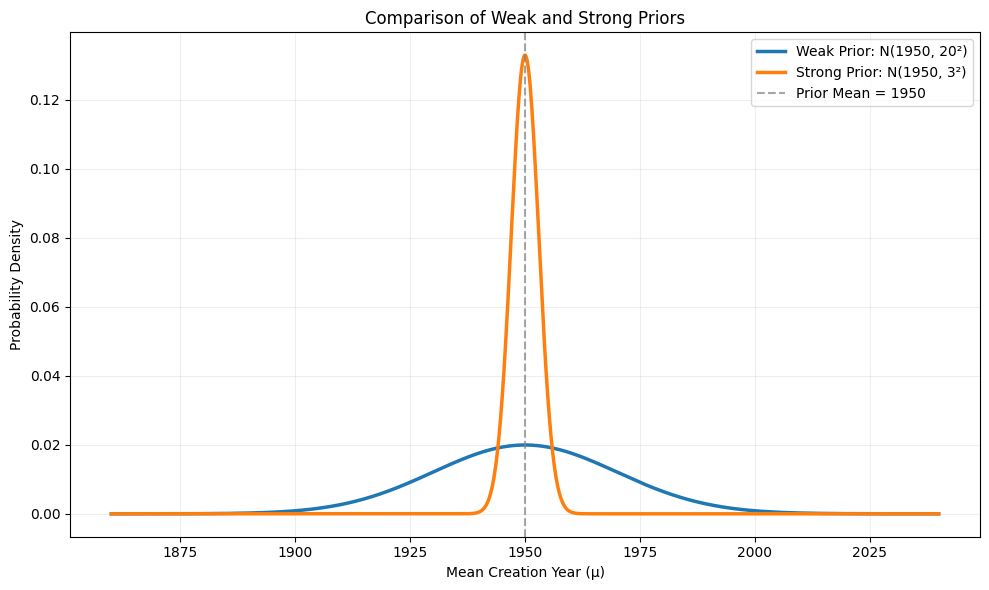

In [7]:

# =========================================
# Slide 1: Prior Distribution Comparison
# =========================================

x = np.linspace(1860, 2040, 1000)

plt.figure(figsize=(10, 6))

# Weak prior
weak_pdf = norm.pdf(
    x,
    loc=priors["Weak Prior"]["mean"],
    scale=priors["Weak Prior"]["sd"]
)

plt.plot(
    x,
    weak_pdf,
    linewidth=2.5,
    label="Weak Prior: N(1950, 20²)"
)

# Strong prior
strong_pdf = norm.pdf(
    x,
    loc=priors["Strong Prior"]["mean"],
    scale=priors["Strong Prior"]["sd"]
)

plt.plot(
    x,
    strong_pdf,
    linewidth=2.5,
    label="Strong Prior: N(1950, 3²)"
)

# Prior mean
plt.axvline(
    1950,
    color="gray",
    linestyle="--",
    alpha=0.7,
    label="Prior Mean = 1950"
)

plt.xlabel("Mean Creation Year (μ)")
plt.ylabel("Probability Density")
plt.title("Comparison of Weak and Strong Priors")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "Slide1_Prior_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [8]:

# =========================================
# Slide 2: MLE vs MAP Experiment
# =========================================

sample_sizes = [100, 1000, 3000]
repetitions = 500

rng = np.random.default_rng(42)

results = []

for n in sample_sizes:

    for i in range(repetitions):

        # 1. Random sampling without replacement
        sample = rng.choice(
            values,
            size=n,
            replace=False
        )

        # 2. MLE: Sample mean
        mle = sample.mean()

        # 3. Estimated sampling variance
        sample_sd = sample.std(ddof=1)

        sampling_var = (
            sample_sd**2 / n
            * (N - n) / (N - 1)
        )

        row = {
            "Sample_Size": n,
            "Iteration": i + 1,
            "MLE": mle,
            "Likelihood_SE": np.sqrt(sampling_var)
        }

        # 4. MAP under each prior
        for name, p in priors.items():

            prior_mu = p["mean"]
            prior_var = p["sd"]**2

            posterior_var = 1 / (
                1 / sampling_var
                + 1 / prior_var
            )

            posterior_mu = posterior_var * (
                mle / sampling_var
                + prior_mu / prior_var
            )

            label = name.split()[0]

            row[f"MAP_{label}"] = posterior_mu
            row[f"Posterior_SD_{label}"] = (
                np.sqrt(posterior_var)
            )

        results.append(row)

map_results = pd.DataFrame(results)

print("Experiment completed!")
print(f"Total experiments: {len(map_results)}")

display(map_results.head().round(3))


Experiment completed!
Total experiments: 1500


,Sample_Size,Iteration,MLE,Likelihood_SE,MAP_Weak,Posterior_SD_Weak,MAP_Strong,Posterior_SD_Strong
0,100,1,1960.720,3.002,1960.484,2.968,1955.357,2.122
1,100,2,1955.410,3.226,1955.273,3.185,1952.509,2.197
2,100,3,1948.675,3.781,1948.721,3.716,1949.488,2.350
3,100,4,1960.810,3.273,1960.528,3.230,1954.935,2.212
4,100,5,1957.845,3.039,1957.668,3.005,1953.871,2.135


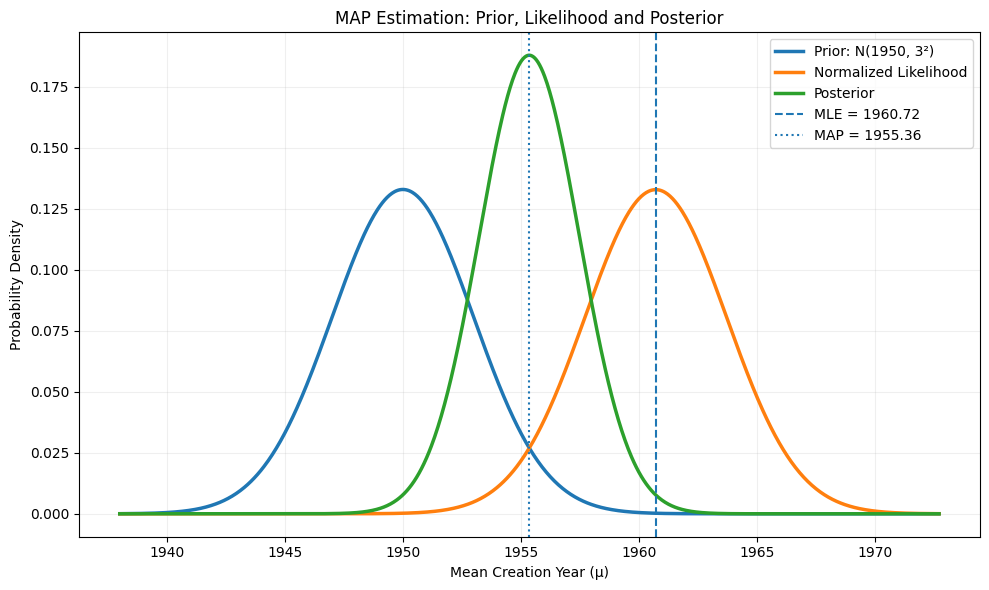

MLE = 1960.720
MAP = 1955.357
Posterior SD = 2.122


In [9]:

# =========================================
# Figure: Prior, Likelihood, Posterior
# =========================================

from scipy.stats import norm

# Select one experiment: n = 100
example = map_results[
    (map_results["Sample_Size"] == 100) &
    (map_results["Iteration"] == 1)
].iloc[0]

# MLE and approximate likelihood
mle = example["MLE"]
likelihood_sd = example["Likelihood_SE"]

# Strong Prior
prior_mu = priors["Strong Prior"]["mean"]
prior_sd = priors["Strong Prior"]["sd"]

# MAP and posterior
map_mu = example["MAP_Strong"]
posterior_sd = example["Posterior_SD_Strong"]

# Plotting range
x_min = min(
    prior_mu - 4*prior_sd,
    mle - 4*likelihood_sd,
    map_mu - 4*posterior_sd
)

x_max = max(
    prior_mu + 4*prior_sd,
    mle + 4*likelihood_sd,
    map_mu + 4*posterior_sd
)

x = np.linspace(x_min, x_max, 1000)

plt.figure(figsize=(10, 6))

# Prior
plt.plot(
    x,
    norm.pdf(x, prior_mu, prior_sd),
    linewidth=2.5,
    label="Prior: N(1950, 3²)"
)

# Normalized likelihood for mu
plt.plot(
    x,
    norm.pdf(x, mle, likelihood_sd),
    linewidth=2.5,
    label="Normalized Likelihood"
)

# Posterior
plt.plot(
    x,
    norm.pdf(x, map_mu, posterior_sd),
    linewidth=2.5,
    label="Posterior"
)

# MLE and MAP reference lines
plt.axvline(
    mle,
    linestyle="--",
    label=f"MLE = {mle:.2f}"
)

plt.axvline(
    map_mu,
    linestyle=":",
    label=f"MAP = {map_mu:.2f}"
)

plt.xlabel("Mean Creation Year (μ)")
plt.ylabel("Probability Density")

plt.title(
    "MAP Estimation: Prior, Likelihood and Posterior"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

plt.savefig(
    "Slide2_MAP_Posterior.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"MLE = {mle:.3f}")
print(f"MAP = {map_mu:.3f}")
print(f"Posterior SD = {posterior_sd:.3f}")
